# Customer Churn Prediction & Business Insights

## 1. Project Overview

This project analyzes customer churn patterns in an Indian telecom customer dataset containing 243,553 customer records.

The analysis combines data cleaning, exploratory data analysis, statistical testing, and machine learning to investigate factors associated with customer churn and evaluate whether the available customer attributes can effectively predict individual churn.

### Objectives

- Analyze overall customer churn and identify important patterns.
- Compare churn across demographic, geographic, usage, financial, and tenure-related segments.
- Apply statistical tests to evaluate differences between churned and non-churned customers.
- Build and evaluate multiple machine learning classification models.
- Identify limitations in the available data and provide actionable business recommendations.

### Tools & Technologies

**Python | Pandas | NumPy | Matplotlib | Seaborn | Scikit-learn | Jupyter Notebook**

In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Data Loading & Understanding

The cleaned dataset is loaded for all analysis in this notebook. The dataset contains customer-level telecom information including demographics, location, registration details, financial attributes, customer usage, telecom partner, and churn status.

The dataset contains **243,553 rows and 14 columns** before feature engineering and modeling.

In [89]:
df = pd.read_csv("../data/cleaned/telecom_churn_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (243553, 14)


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44.0,45.0,NaN,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62.0,39.0,5973.0,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49.0,24.0,193.0,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80.0,25.0,9377.0,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78.0,15.0,1393.0,0


## 3. Data Quality & Cleaning

The raw data was cleaned before this analysis. The checks below verify missing values, duplicate records, duplicate customer IDs, and invalid negative usage values in the cleaned dataset.

In [90]:
df.isnull().sum()

customer_id                0
telecom_partner            0
gender                     0
age                        0
state                      0
city                       0
pincode                    0
date_of_registration       0
num_dependents             0
estimated_salary           0
calls_made              6713
sms_sent                7375
data_used               6050
churn                      0
dtype: int64

In [91]:
df.duplicated().sum()


0

In [92]:
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())

Duplicate customer IDs: 0


In [93]:
numeric_columns = [
    "age",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used"
]

(df[numeric_columns] < 0).sum()

age                 0
num_dependents      0
estimated_salary    0
calls_made          0
sms_sent            0
data_used           0
dtype: int64

In [94]:
df[[
    "age",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used"
]].describe()

,age,num_dependents,estimated_salary,calls_made,sms_sent,data_used
count,243553.000000,243553.000000,243553.000000,236840.000000,236178.000000,237503.000000
mean,46.077609,1.997500,85021.137839,50.512384,24.765681,5128.756125
std,16.444029,1.414941,37508.963233,28.462247,14.198159,2852.135577
min,18.000000,0.000000,20000.000000,0.000000,0.000000,0.000000
25%,32.000000,1.000000,52585.000000,26.000000,13.000000,2675.000000
50%,46.000000,2.000000,84990.000000,50.000000,25.000000,5112.000000
75%,60.000000,3.000000,117488.000000,75.000000,37.000000,7557.000000
max,74.000000,4.000000,149999.000000,108.000000,53.000000,10991.000000


## 4. Exploratory Data Analysis

### 4.1 Overall Churn

In [95]:
churn_counts = df["churn"].value_counts()

churn_counts

churn
0    194726
1     48827
Name: count, dtype: int64

In [96]:
churn_rate = df["churn"].mean() * 100

print(f"Overall Churn Rate: {churn_rate:.2f}%")

Overall Churn Rate: 20.05%


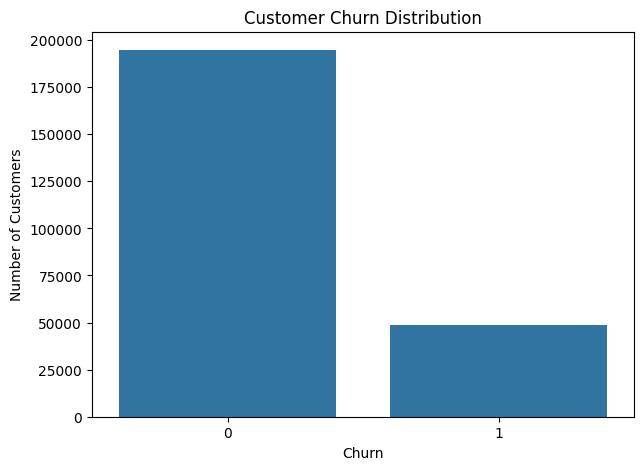

In [97]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [98]:
churn_percentage = (
    df["churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

churn_percentage

churn
0    79.95
1    20.05
Name: proportion, dtype: float64

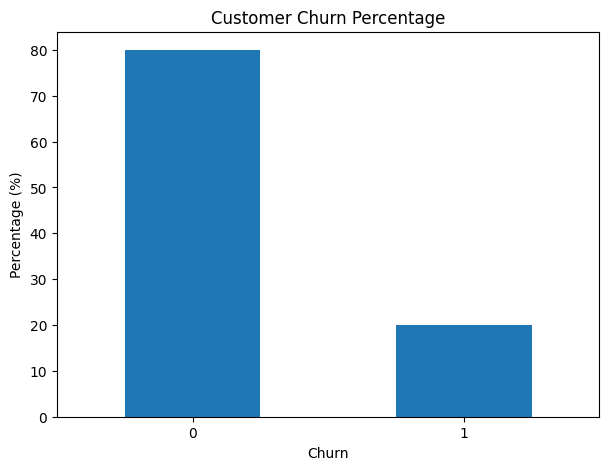

In [99]:
churn_percentage.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Customer Churn Percentage")
plt.xlabel("Churn")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.show()

### Business Insight

The dataset shows an overall customer churn rate of approximately 20.05%.
This indicates that around one-fifth of the customer base is classified as churned.
Further analysis will investigate whether churn varies by telecom partner,
customer demographics, geographic location, and usage behavior.

### 4.2 Churn by Telecom Partner

In [100]:
partner_churn = (
    df.groupby("telecom_partner")["churn"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

partner_churn

telecom_partner
Airtel          20.37
Reliance Jio    20.02
Vodafone        19.95
BSNL            19.86
Name: churn, dtype: float64

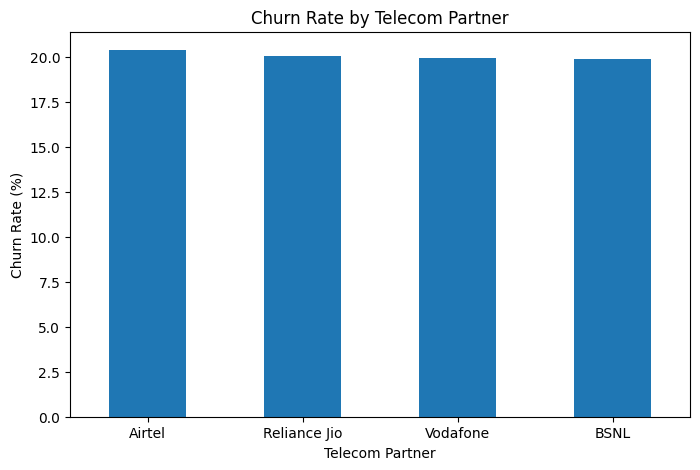

In [101]:
partner_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Telecom Partner")
plt.xlabel("Telecom Partner")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [102]:
partner_summary = (
    df.groupby("telecom_partner")
    .agg(
        customers=("customer_id", "count"),
        churned_customers=("churn", "sum"),
        churn_rate=("churn", "mean")
    )
)

partner_summary["churn_rate"] = (
    partner_summary["churn_rate"] * 100
).round(2)

partner_summary.sort_values(
    "churn_rate",
    ascending=False
)

,customers,churned_customers,churn_rate
telecom_partner,,,
Airtel,60905,12404,20.37
Reliance Jio,61123,12234,20.02
Vodafone,60802,12129,19.95
BSNL,60723,12060,19.86


### Business Insight — Telecom Partner

Churn rates are relatively consistent across the four telecom partners,
with only a small difference between the observed rates. This suggests
that telecom partner alone may not be a strong differentiating factor
for customer churn in this dataset.

Further analysis should examine customer demographics, geographic
segments, and usage behavior to identify stronger relationships with churn.


### 4.3 Churn by Gender

In [103]:
gender_churn = (
    df.groupby("gender")["churn"]
    .mean()
    .mul(100)
    .round(2)
)

gender_churn

gender
F    20.30
M    19.88
Name: churn, dtype: float64

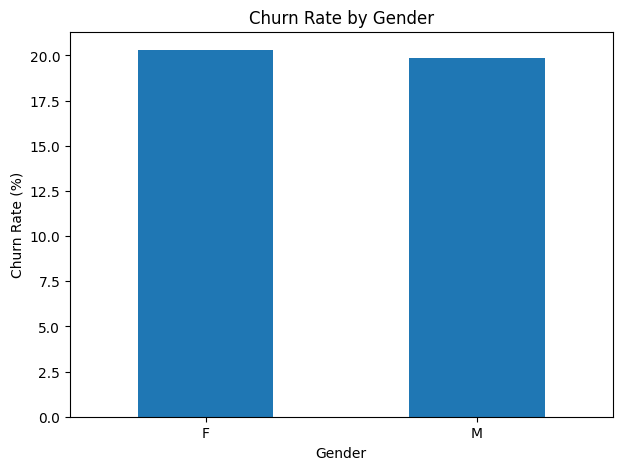

In [104]:
gender_churn.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [105]:
gender_summary = (
    df.groupby("gender")
    .agg(
        customers=("customer_id", "count"),
        churned_customers=("churn", "sum"),
        churn_rate=("churn", "mean")
    )
)

gender_summary["churn_rate"] = (
    gender_summary["churn_rate"] * 100
).round(2)

gender_summary

,customers,churned_customers,churn_rate
gender,,,
F,97576,19805,20.30
M,145977,29022,19.88


### Business Insight — Gender

Churn rates are similar across the two gender groups. Female customers
have an observed churn rate of 20.30%, compared with 19.88% for male
customers, a difference of approximately 0.42 percentage points.

This suggests that gender alone does not show a substantial difference
in churn behavior in this dataset.

### 4.4 Churn by Age Group

In [106]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 18, 25, 35, 45, 55, 65, 100],
    labels=[
        "Under 18",
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "65+"
    ]
)

In [107]:
df["age_group"].value_counts().sort_index()

age_group
Under 18     4128
18-25       29898
26-35       42302
36-45       42649
46-55       43005
56-65       42953
65+         38618
Name: count, dtype: int64

In [108]:
age_churn = (
    df.groupby("age_group", observed=True)["churn"]
    .mean()
    .mul(100)
    .round(2)
)

age_churn

age_group
Under 18    19.86
18-25       19.95
26-35       20.06
36-45       20.18
46-55       19.96
56-65       20.03
65+         20.10
Name: churn, dtype: float64

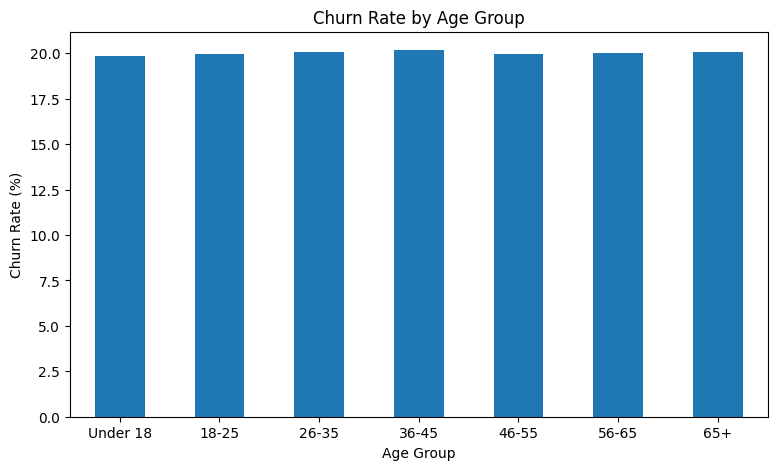

In [109]:
age_churn.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [110]:
age_summary = (
    df.groupby("age_group", observed=True)
    .agg(
        customers=("customer_id", "count"),
        churned_customers=("churn", "sum"),
        churn_rate=("churn", "mean")
    )
)

age_summary["churn_rate"] = (
    age_summary["churn_rate"] * 100
).round(2)

age_summary

,customers,churned_customers,churn_rate
age_group,,,
Under 18,4128,820,19.86
18-25,29898,5964,19.95
26-35,42302,8485,20.06
36-45,42649,8605,20.18
46-55,43005,8584,19.96
56-65,42953,8605,20.03
65+,38618,7764,20.10


### Business Insight — Age Group

Churn rates remain relatively consistent across all age groups, ranging
from 19.86% to 20.18%. The observed variation is small, indicating that
age group alone does not show a substantial difference in churn behavior
within this dataset.

### 4.5 Churn by State

In [111]:
state_churn = (
    df.groupby("state")["churn"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

state_churn

state
Jharkhand            21.12
Karnataka            20.71
Mizoram              20.65
Uttarakhand          20.42
Himachal Pradesh     20.41
Madhya Pradesh       20.38
Assam                20.30
Odisha               20.25
Nagaland             20.23
Rajasthan            20.22
Telangana            20.11
Manipur              20.11
Uttar Pradesh        20.08
Sikkim               20.07
Haryana              20.03
Gujarat              20.02
Goa                  19.96
Tamil Nadu           19.94
Maharashtra          19.91
Arunachal Pradesh    19.89
Andhra Pradesh       19.85
Meghalaya            19.75
Bihar                19.63
Kerala               19.53
Tripura              19.48
Punjab               19.43
Chhattisgarh         19.43
West Bengal          19.40
Name: churn, dtype: float64

In [112]:
print("Highest observed state churn rates:")
print(state_churn.head(10))

print("\nLowest observed state churn rates:")
print(state_churn.tail(10))

Highest observed state churn rates:
state
Jharkhand           21.12
Karnataka           20.71
Mizoram             20.65
Uttarakhand         20.42
Himachal Pradesh    20.41
Madhya Pradesh      20.38
Assam               20.30
Odisha              20.25
Nagaland            20.23
Rajasthan           20.22
Name: churn, dtype: float64

Lowest observed state churn rates:
state
Maharashtra          19.91
Arunachal Pradesh    19.89
Andhra Pradesh       19.85
Meghalaya            19.75
Bihar                19.63
Kerala               19.53
Tripura              19.48
Punjab               19.43
Chhattisgarh         19.43
West Bengal          19.40
Name: churn, dtype: float64


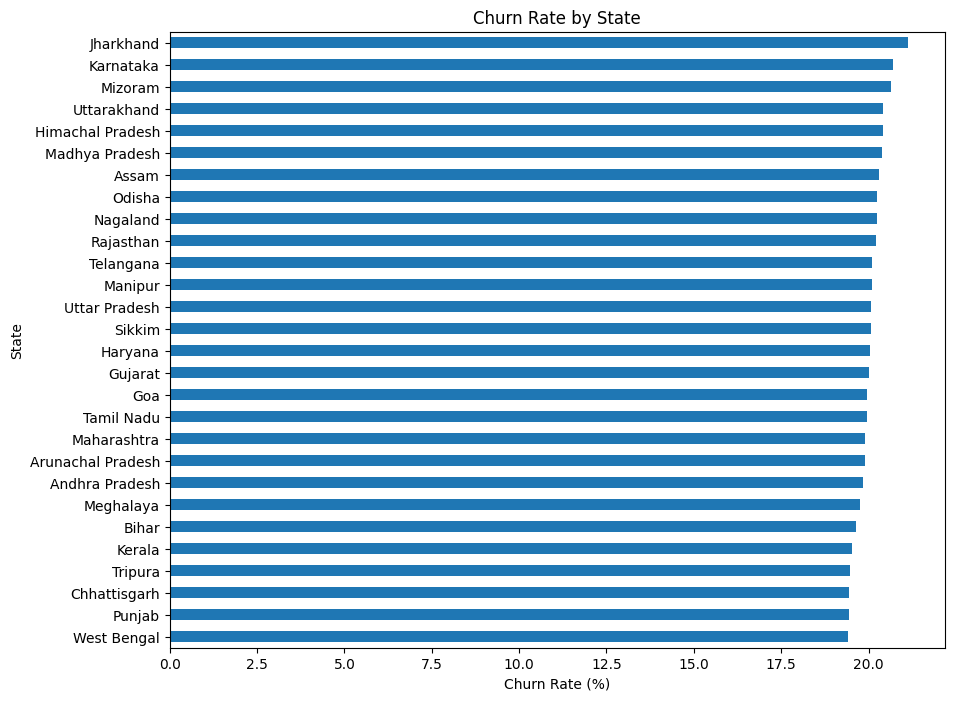

In [113]:
state_churn.sort_values().plot(
    kind="barh",
    figsize=(10, 8)
)

plt.title("Churn Rate by State")
plt.xlabel("Churn Rate (%)")
plt.ylabel("State")

plt.show()

In [114]:
state_summary = (
    df.groupby("state")
    .agg(
        customers=("customer_id", "count"),
        churned_customers=("churn", "sum"),
        churn_rate=("churn", "mean")
    )
)

state_summary["churn_rate"] = (
    state_summary["churn_rate"] * 100
).round(2)

state_summary = state_summary.sort_values(
    "churn_rate",
    ascending=False
)

state_summary


,customers,churned_customers,churn_rate
state,,,
Jharkhand,8755,1849,21.12
Karnataka,8845,1832,20.71
Mizoram,8689,1794,20.65
Uttarakhand,8856,1808,20.42
Himachal Pradesh,8682,1772,20.41
Madhya Pradesh,8817,1797,20.38
Assam,8547,1735,20.30
Odisha,8712,1764,20.25
Nagaland,8562,1732,20.23


### Business Insight — State

State-level churn rates show some geographic variation, but most states
remain close to the overall churn rate of approximately 20%. The observed
state-level rates range from 19.40% to 21.12%, suggesting that geography
may provide some segmentation value, but the differences are relatively
modest.

### 4.6 Usage Behavior and Churn

In [115]:
usage_summary = (
    df.groupby("churn")
    .agg(
        avg_calls=("calls_made", "mean"),
        avg_sms=("sms_sent", "mean"),
        avg_data=("data_used", "mean")
    )
    .round(2)
)

usage_summary

,avg_calls,avg_sms,avg_data
churn,,,
0,50.48,24.78,5126.50
1,50.64,24.70,5137.77


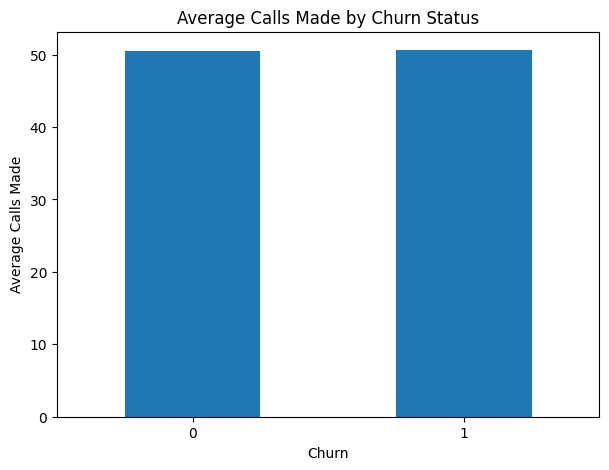

In [116]:
df.groupby("churn")["calls_made"].mean().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Calls Made by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Average Calls Made")
plt.xticks(rotation=0)

plt.show()

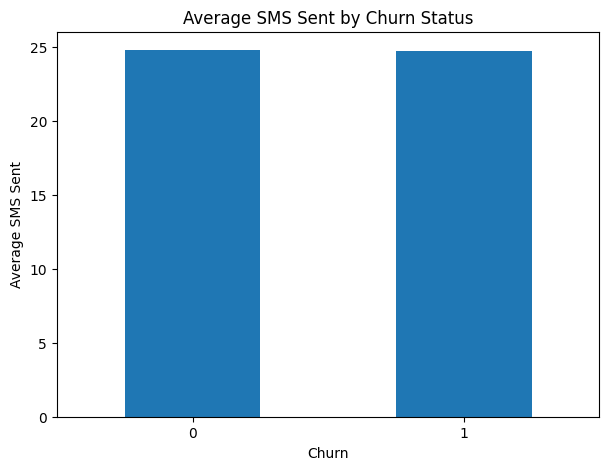

In [117]:
df.groupby("churn")["sms_sent"].mean().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average SMS Sent by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Average SMS Sent")
plt.xticks(rotation=0)

plt.show()

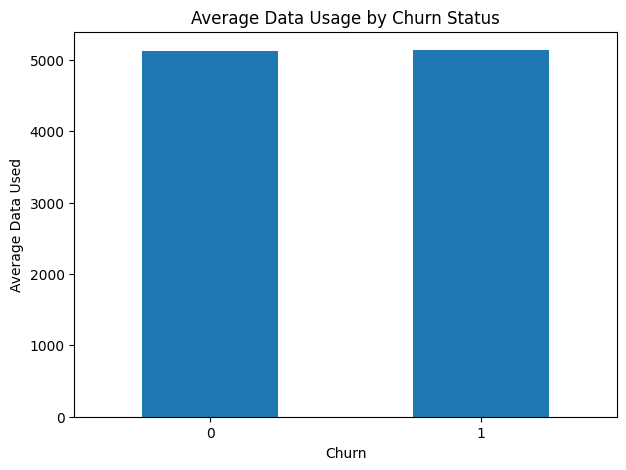

In [118]:
df.groupby("churn")["data_used"].mean().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Data Usage by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Average Data Used")
plt.xticks(rotation=0)

plt.show()

In [119]:
usage_by_churn = (
    df.groupby("churn")["data_used"]
    .describe()
    .round(2)
)

usage_by_churn

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,189930.0,5126.50,2855.68,0.0,2667.0,5111.0,7561.0,10991.0
1,47573.0,5137.77,2837.97,0.0,2707.0,5118.0,7539.0,10990.0


In [120]:
usage_distribution = (
    df.groupby("churn")[["calls_made", "sms_sent"]]
    .describe()
    .round(2)
)

usage_distribution

calls_made                                              sms_sent         \
           count   mean    std  min   25%   50%   75%    max     count   mean   
churn                                                                           
0       189375.0  50.48  28.48  0.0  26.0  50.0  75.0  108.0  188887.0  24.78   
1        47465.0  50.64  28.39  0.0  26.0  51.0  75.0  108.0   47291.0  24.70   

                                          
        std  min   25%   50%   75%   max  
churn                                     
0      14.2  0.0  13.0  25.0  37.0  53.0  
1      14.2  0.0  12.0  25.0  37.0  53.0

### Business Insight — Usage Behavior

Average usage levels are very similar between churned and non-churned
customers. Churned customers average 50.64 calls and 5,137.77 units of
data usage, compared with 50.48 calls and 5,126.50 units for non-churned
customers. Average SMS usage is also similar.

Therefore, simple average usage measures do not show a substantial
difference between the two churn groups in this dataset.

### 4.7 Salary and Dependents

In [121]:
salary_summary = (
    df.groupby("churn")["estimated_salary"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)

salary_summary


,mean,median,min,max
churn,,,,
0,85083.73,85051.0,20000,149999
1,84771.53,84768.0,20002,149997


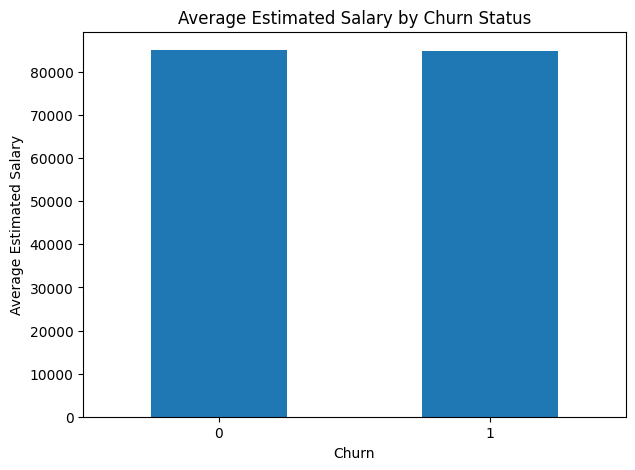

In [122]:
df.groupby("churn")["estimated_salary"].mean().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Estimated Salary by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Average Estimated Salary")
plt.xticks(rotation=0)

plt.show()

In [123]:
dependent_summary = (
    df.groupby("churn")["num_dependents"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)

dependent_summary

,mean,median,min,max
churn,,,,
0,2.00,2.0,0,4
1,1.99,2.0,0,4


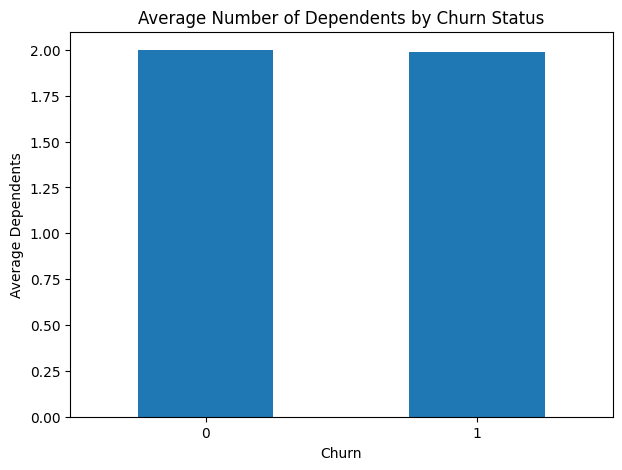

In [124]:
df.groupby("churn")["num_dependents"].mean().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Number of Dependents by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Average Dependents")
plt.xticks(rotation=0)

plt.show()

### Business Insight — Salary and Dependents

Estimated salary is similar for churned and non-churned customers, with
mean salaries of 84,771.53 and 85,083.73 respectively. The median and
range are also very similar.

The average number of dependents is almost identical between the two
groups at 1.99 for churned customers and 2.00 for non-churned customers.

These variables therefore do not show substantial differences between
the observed churn groups when compared using basic summary statistics.

### 4.8 Customer Tenure

In [125]:
df["date_of_registration"] = pd.to_datetime(
    df["date_of_registration"],
    errors="coerce"
)

print("Registration date range:", df["date_of_registration"].min(), "to", df["date_of_registration"].max())

Registration date range: 2020-01-01 00:00:00 to 2023-05-04 00:00:00


In [126]:
analysis_date = df["date_of_registration"].max()

df["tenure_days"] = (
    analysis_date - df["date_of_registration"]
).dt.days

df["tenure_months"] = (
    df["tenure_days"] / 30.44
).round(1)

df[["date_of_registration", "tenure_days", "tenure_months", "churn"]].head()

,date_of_registration,tenure_days,tenure_months,churn
0,2020-01-01,1219,40.0,0
1,2020-01-01,1219,40.0,0
2,2020-01-01,1219,40.0,1
3,2020-01-01,1219,40.0,1
4,2020-01-01,1219,40.0,0


In [127]:

df["tenure_group"] = pd.cut(
    df["tenure_months"],
    bins=[-1, 6, 12, 24, 36, 60, float("inf")],
    labels=[
        "0-6 months",
        "7-12 months",
        "13-24 months",
        "25-36 months",
        "37-60 months",
        "60+ months"
    ]
)

In [128]:
df["tenure_group"].value_counts().sort_index()

tenure_group
0-6 months      36763
7-12 months     36363
13-24 months    73126
25-36 months    72925
37-60 months    24376
60+ months          0
Name: count, dtype: int64

In [129]:
tenure_churn = (
    df.groupby("tenure_group", observed=True)["churn"]
    .mean()
    .mul(100)
    .round(2)
)

tenure_churn

tenure_group
0-6 months      20.13
7-12 months     19.95
13-24 months    20.16
25-36 months    20.05
37-60 months    19.74
Name: churn, dtype: float64

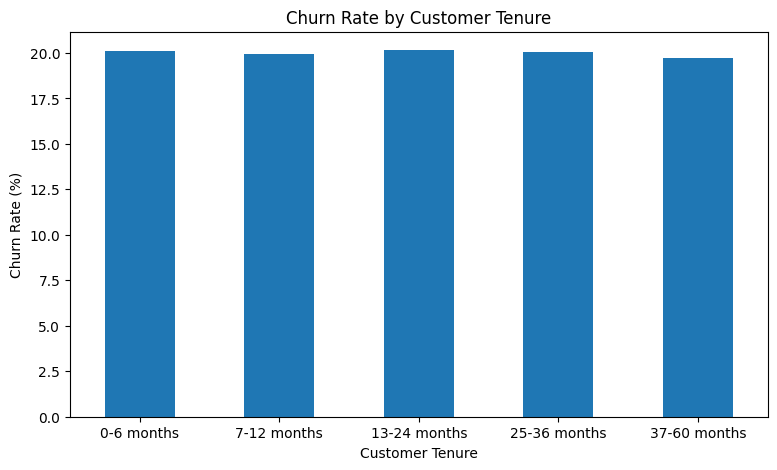

In [130]:
tenure_churn.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

### 4.9 State–Partner and Demographic Segments

In [131]:
state_partner_churn = (
    df.groupby(["state", "telecom_partner"])["churn"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

state_partner_churn.head(15)

state             telecom_partner
Jharkhand         Reliance Jio       23.21
Madhya Pradesh    Vodafone           22.61
Himachal Pradesh  Airtel             22.52
Mizoram           Airtel             22.29
Assam             Airtel             21.72
Rajasthan         Airtel             21.64
Uttarakhand       Airtel             21.49
Jharkhand         Vodafone           21.33
Manipur           Reliance Jio       21.27
Uttar Pradesh     Reliance Jio       21.24
Uttarakhand       BSNL               21.15
Uttar Pradesh     Vodafone           21.12
Karnataka         Reliance Jio       21.08
Telangana         Vodafone           21.04
Himachal Pradesh  Vodafone           20.96
Name: churn, dtype: float64

In [132]:
age_gender_churn = (
    df.groupby(["age_group", "gender"], observed=True)["churn"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

age_gender_churn

age_group  gender
Under 18   F         20.80
36-45      F         20.65
18-25      F         20.46
46-55      F         20.32
65+        F         20.28
26-35      M         20.09
56-65      F         20.05
           M         20.03
26-35      F         20.02
65+        M         19.98
36-45      M         19.86
46-55      M         19.72
18-25      M         19.61
Under 18   M         19.23
Name: churn, dtype: float64

Age and gender combinations showed modest variation in churn rates, with female customers generally recording slightly higher churn across several age groups. However, the overall differences remained relatively small, indicating that demographic characteristics alone may not strongly explain customer churn.

In [133]:
city_summary = (
    df.groupby("city")
    .agg(
        customers=("customer_id", "count"),
        churned_customers=("churn", "sum"),
        churn_rate=("churn", "mean")
    )
)

city_summary["churn_rate"] = (
    city_summary["churn_rate"] * 100
).round(2)

city_summary = city_summary.sort_values(
    "churn_rate",
    ascending=False
)

city_summary

,customers,churned_customers,churn_rate
city,,,
Hyderabad,40698,8309,20.42
Kolkata,40661,8196,20.16
Mumbai,40386,8141,20.16
Bangalore,40603,8141,20.05
Chennai,40749,8050,19.76
Delhi,40456,7990,19.75


In [134]:
df["registration_year"] = df["date_of_registration"].dt.year

year_summary = (
    df.groupby("registration_year")
    .agg(
        customers=("customer_id", "count"),
        churned_customers=("churn", "sum"),
        churn_rate=("churn", "mean")
    )
)

year_summary["churn_rate"] = (year_summary["churn_rate"] * 100).round(2)
year_summary

,customers,churned_customers,churn_rate
registration_year,,,
2020,73126,14558,19.91
2021,72926,14708,20.17
2022,72926,14644,20.08
2023,24575,4917,20.01


## 5. Statistical Analysis

In [135]:
numeric_columns = [
    "age",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used",
    "tenure_months",
    "churn"
]

correlation = df[numeric_columns].corr().round(2)

correlation

,age,num_dependents,estimated_salary,calls_made,sms_sent,data_used,tenure_months,churn
age,1.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0
num_dependents,0.0,1.0,0.0,-0.0,0.0,0.0,0.0,-0.0
estimated_salary,-0.0,0.0,1.0,-0.0,0.0,-0.0,-0.0,-0.0
calls_made,-0.0,-0.0,-0.0,1.0,0.0,0.0,-0.0,0.0
sms_sent,-0.0,0.0,0.0,0.0,1.0,-0.0,-0.0,-0.0
data_used,0.0,0.0,-0.0,0.0,-0.0,1.0,-0.0,0.0
tenure_months,0.0,0.0,-0.0,-0.0,-0.0,-0.0,1.0,-0.0
churn,0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,1.0


In [136]:
from scipy.stats import chi2_contingency

partner_table = pd.crosstab(
    df["telecom_partner"],
    df["churn"]
)

chi2, p_value, dof, expected = chi2_contingency(partner_table)

print("Chi-square:", chi2)
print("p-value:", p_value)

Chi-square: 5.59247200801428
p-value: 0.13321120079763688


In [137]:
categorical_columns = [
    "gender",
    "city",
    "state"
]

for column in categorical_columns:
    table = pd.crosstab(df[column], df["churn"])
    
    chi2, p_value, dof, expected = chi2_contingency(table)
    
    print(f"{column}:")
    print(f"Chi-square = {chi2:.4f}")
    print(f"p-value = {p_value:.6f}")
    print()

gender:
Chi-square = 6.2818
p-value = 0.012198

city:
Chi-square = 8.4735
p-value = 0.131997

state:
Chi-square = 25.2151
p-value = 0.562410



In [138]:
from scipy.stats import mannwhitneyu

numerical_columns = [
    "age",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used",
    "tenure_months"
]

for column in numerical_columns:
    group_0 = df.loc[df["churn"] == 0, column].dropna()
    group_1 = df.loc[df["churn"] == 1, column].dropna()

    statistic, p_value = mannwhitneyu(
        group_0,
        group_1,
        alternative="two-sided"
    )

    print(f"{column}:")
    print(f"U statistic = {statistic:.2f}")
    print(f"p-value = {p_value:.6f}")
    print()

age:
U statistic = 4748190676.50
p-value = 0.678751

num_dependents:
U statistic = 4771030244.50
p-value = 0.209333

estimated_salary:
U statistic = 4776771584.50
p-value = 0.100314

calls_made:
U statistic = 4479270956.00
p-value = 0.257812

sms_sent:
U statistic = 4480615059.50
p-value = 0.281142

data_used:
U statistic = 4507275213.50
p-value = 0.432581

tenure_months:
U statistic = 4765268468.00
p-value = 0.414918



In [139]:
age_partner_churn = (
    df.groupby(["age_group", "telecom_partner"], observed=True)["churn"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

age_partner_churn


age_group  telecom_partner
36-45      Airtel             21.05
26-35      Airtel             20.75
Under 18   BSNL               20.65
56-65      Airtel             20.59
65+        BSNL               20.44
18-25      Vodafone           20.39
46-55      Reliance Jio       20.33
Under 18   Vodafone           20.23
26-35      Vodafone           20.13
65+        Vodafone           20.09
56-65      Reliance Jio       20.09
36-45      BSNL               20.07
18-25      Reliance Jio       20.01
           Airtel             19.97
65+        Airtel             19.97
46-55      BSNL               19.95
36-45      Reliance Jio       19.93
65+        Reliance Jio       19.92
26-35      Reliance Jio       19.90
46-55      Airtel             19.80
           Vodafone           19.77
56-65      Vodafone           19.77
           BSNL               19.68
Under 18   Airtel             19.68
36-45      Vodafone           19.67
26-35      BSNL               19.46
18-25      BSNL               19.41
U

## 6. Feature Preparation

The target variable is `churn`. Customer ID, pincode, raw registration date, and EDA-only derived grouping columns are excluded from the model features.

In [140]:
features = [
    "telecom_partner",
    "gender",
    "age",
    "state",
    "city",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used",
    "tenure_months",
    "registration_year"
]

In [141]:
target = "churn"

In [142]:
X = df[features]
y = df["churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (243553, 12)
Target shape: (243553,)


### Train-Test Split

In [143]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (194842, 12)
Testing features: (48711, 12)
Training target: (194842,)
Testing target: (48711,)


### Preprocessing Pipeline

In [144]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_features = [
    "age",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used",
    "tenure_months",
    "registration_year"
]

categorical_features = [
    "telecom_partner",
    "gender",
    "state",
    "city"
]

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [145]:
print("Preprocessor created successfully!")

Preprocessor created successfully!


## 7. Model Training

### 7.1 Logistic Regression

In [146]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Logistic Regression model created successfully!")

Logistic Regression model created successfully!


In [147]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### 7.2 Random Forest

In [148]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [149]:
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


### 7.3 Class-Weighted Logistic Regression

In [150]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

balanced_logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

balanced_logistic_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### 7.4 Gradient Boosting

In [151]:
dense_numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

dense_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

dense_preprocessor = ColumnTransformer([
    ("num", dense_numerical_pipeline, numerical_features),
    ("cat", dense_categorical_pipeline, categorical_features)
])

In [152]:
from sklearn.ensemble import HistGradientBoostingClassifier

gradient_boosting_model = Pipeline([
    ("preprocessor", dense_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    ))
])

In [153]:
gradient_boosting_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## 8. Model Evaluation

### 8.1 Logistic Regression

In [154]:
y_pred = logistic_model.predict(X_test)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

Predictions generated successfully!
Number of predictions: 48711


In [155]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 0.7995
Precision: 0.0000
Recall   : 0.0000
F1 Score : 0.0000


c:\Users\Dhruv Srivastava\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [156]:
print("Actual churn distribution:")
print(y_test.value_counts())

print("\nPredicted churn distribution:")
print(pd.Series(y_pred).value_counts())

Actual churn distribution:
churn
0    38946
1     9765
Name: count, dtype: int64

Predicted churn distribution:
0    48711
Name: count, dtype: int64


In [157]:
y_proba = logistic_model.predict_proba(X_test)[:, 1]

print("Minimum probability:", y_proba.min())
print("Maximum probability:", y_proba.max())
print("Average probability:", y_proba.mean())

Minimum probability: 0.17838844559328718
Maximum probability: 0.2227434308389068
Average probability: 0.20040522599827298


In [158]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_proba)

print(f"ROC-AUC: {roc_auc:.4f}")

ROC-AUC: 0.5059


### 8.2 Random Forest

In [159]:
y_pred_rf = random_forest_model.predict(X_test)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred_rf))


Predictions generated successfully!
Number of predictions: 48711


In [160]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1 Score : {f1_rf:.4f}")

Accuracy : 0.7995
Precision: 0.0000
Recall   : 0.0000
F1 Score : 0.0000


c:\Users\Dhruv Srivastava\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [161]:
y_proba_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Minimum probability:", y_proba_rf.min())
print("Maximum probability:", y_proba_rf.max())
print("Average probability:", y_proba_rf.mean())

Minimum probability: 0.15326517539856424
Maximum probability: 0.24798153410585497
Average probability: 0.20046830337025942


In [162]:
from sklearn.metrics import roc_auc_score

roc_auc_rf = roc_auc_score(y_test, y_proba_rf)

print(f"Random Forest ROC-AUC: {roc_auc_rf:.4f}")

Random Forest ROC-AUC: 0.5069


### 8.3 Class-Weighted Logistic Regression

In [163]:
y_pred_balanced = balanced_logistic_model.predict(X_test)

y_proba_balanced = balanced_logistic_model.predict_proba(X_test)[:, 1]

In [164]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred_balanced))
print("Precision:", precision_score(y_test, y_pred_balanced))
print("Recall:", recall_score(y_test, y_pred_balanced))
print("F1 Score:", f1_score(y_test, y_pred_balanced))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_balanced))

Accuracy: 0.5041982303791751
Precision: 0.20128737541528238
Recall: 0.49636456733230927
F1 Score: 0.28642340079775447
ROC-AUC: 0.5058296139107785


### Threshold Analysis

In [165]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_proba_balanced
)

threshold_results = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision[:-1],
    "recall": recall[:-1]
})

threshold_results[
    threshold_results["recall"].between(0.45, 0.55)
].sort_values("precision", ascending=False).head(10)

,threshold,precision,recall
22409,0.498977,0.202722,0.546032
22408,0.498977,0.202715,0.546032
22368,0.498957,0.202710,0.546851
22363,0.498955,0.202710,0.546953
22412,0.498979,0.202707,0.545929
22407,0.498976,0.202707,0.546032
22328,0.498940,0.202706,0.547670
22367,0.498956,0.202703,0.546851
22362,0.498954,0.202702,0.546953
22347,0.498949,0.202701,0.547261


The threshold analysis shows that increasing recall does not produce a meaningful improvement in precision. This is consistent with the ROC-AUC result near 0.50 and indicates limited separation between churned and non-churned customers.

### 8.4 Gradient Boosting

In [166]:
y_pred_gb = gradient_boosting_model.predict(X_test)

y_proba_gb = gradient_boosting_model.predict_proba(X_test)[:, 1]

In [167]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:", f1_score(y_test, y_pred_gb))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_gb))

Accuracy: 0.7995319332388988
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.5005223415282505


c:\Users\Dhruv Srivastava\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [168]:
print("Minimum probability:", y_proba_gb.min())
print("Maximum probability:", y_proba_gb.max())
print("Average probability:", y_proba_gb.mean())

Minimum probability: 0.1428755006505806
Maximum probability: 0.30274734371879286
Average probability: 0.2004532914565754


In [169]:
print("Predicted churners:", (y_pred_gb == 1).sum())
print("Predicted non-churners:", (y_pred_gb == 0).sum())

Predicted churners: 0
Predicted non-churners: 48711


## Modeling Results

Logistic Regression, Random Forest, and Gradient Boosting models produced ROC-AUC values close to 0.50, indicating limited ability to distinguish churners from non-churners using the available customer demographic, geographic, registration, financial, dependency, and usage features.

Class-weighted Logistic Regression increased churn recall to 49.64%, but ROC-AUC remained essentially unchanged at 0.5058. This suggests that changing class weights altered the classification behavior without materially improving the underlying predictive signal.

Overall, the available features provide limited predictive power for individual customer churn in this dataset.

The dataset may simply lack variables that capture the actual reasons behind churn, such as customer complaints, network/service quality, pricing changes, recharge behavior, plan changes, support interactions, or customer satisfaction—but we should present these as potential missing variables, not as confirmed causes, because we haven't measured them in this dataset.

## Model Comparison

In [170]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Balanced Logistic Regression",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_balanced),
        accuracy_score(y_test, y_pred_gb)
    ],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0),
        precision_score(y_test, y_pred_balanced, zero_division=0),
        precision_score(y_test, y_pred_gb, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_gb)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_gb)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, logistic_model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, y_proba_rf),
        roc_auc_score(y_test, y_proba_balanced),
        roc_auc_score(y_test, y_proba_gb)
    ]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7995,0.0000,0.0000,0.0000,0.5059
1,Random Forest,0.7995,0.0000,0.0000,0.0000,0.5069
2,Balanced Logistic Regression,0.5042,0.2013,0.4964,0.2864,0.5058
3,Gradient Boosting,0.7995,0.0000,0.0000,0.0000,0.5005


### Model Comparison Insights

The four classification approaches produced ROC-AUC values close to 0.50, indicating limited ability to distinguish churners from non-churners using the available features.

At the default 0.50 probability threshold, Logistic Regression, Random Forest, and Gradient Boosting predicted no customers as churners. Their accuracy of approximately 79.95% mainly reflects the class distribution, where non-churners represent approximately 80% of the dataset.

Class-weighted Logistic Regression changed the classification behavior, increasing churn recall to 49.64% and precision to 20.13%. However, its ROC-AUC remained at 0.5058, showing that the underlying predictive discrimination did not materially improve.

Overall, the available features provide limited predictive signal for individual customer churn in this dataset.

## Confusion Matrix

In [171]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_balanced)

print(cm)

[[19713 19233]
 [ 4918  4847]]


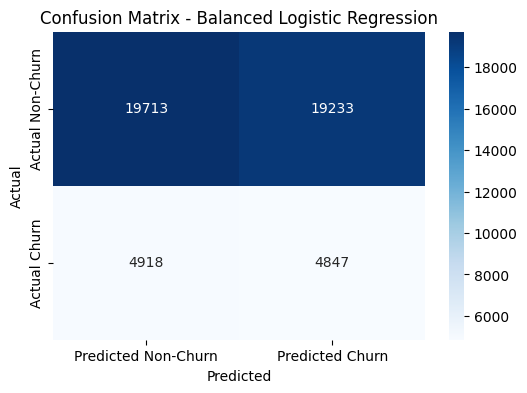

In [172]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Non-Churn", "Predicted Churn"],
    yticklabels=["Actual Non-Churn", "Actual Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.show()

### Confusion Matrix Interpretation

The Balanced Logistic Regression correctly identified 4,847 churners (True Positives) and 19,713 non-churners (True Negatives). However, it incorrectly classified 19,233 non-churners as churners (False Positives) and missed 4,918 actual churners (False Negatives).

The model therefore captured 49.64% of actual churners, consistent with its recall score. However, the high number of false positives resulted in a precision of only 20.13%. This indicates that the model's ability to identify churners comes with a substantial number of incorrect churn-risk classifications.

## Business Insights

This section summarizes the key business findings identified from customer churn patterns across telecom partners, demographics, geography, customer usage, tenure, and other available customer attributes.

### 1. Overall Customer Churn

Out of 243,553 customers, 48,827 customers were classified as churned, resulting in an overall churn rate of approximately 20.05%. Non-churned customers accounted for approximately 79.95% of the dataset.

This establishes a significant churn segment that warrants further analysis of customer characteristics and behavioral patterns.

### 2. Telecom Partner Shows Limited Churn Variation

Churn rates were relatively similar across telecom partners. Airtel recorded the highest churn rate at 20.37%, while BSNL recorded the lowest at 19.86%.

The difference of approximately 0.51 percentage points suggests that telecom partner alone does not strongly differentiate churn behavior in this dataset.

### 3. Geographic Differences Are Relatively Small

Churn rates varied across the 28 states in the dataset. Jharkhand recorded the highest churn rate at 21.12%, while West Bengal recorded the lowest at 19.40%.

Although some geographic variation exists, the overall spread of 1.72 percentage points indicates that state-level differences are relatively modest.

### 4. Usage Behavior Is Very Similar Across Churn Groups

Average calls, SMS usage, and data consumption were very similar between churned and non-churned customers. Churned customers averaged 50.64 calls, 24.70 SMS messages, and 5,137.77 units of data usage, compared with 50.48 calls, 24.78 SMS messages, and 5,126.50 units among non-churned customers.

These small differences suggest that the available usage measures do not provide strong separation between the two churn groups.

### 5. Age and Gender Show Limited Churn Differences

Churn rates were relatively consistent across age groups, ranging from 19.86% among customers under 18 to 20.18% among customers aged 36–45. The overall variation across age groups was small.

Gender differences were also limited. Female customers had a churn rate of 20.30%, compared with 19.88% for male customers, a difference of approximately 0.42 percentage points.

Overall, age and gender show limited practical differences in churn rates within this dataset.

### 6. Salary and Number of Dependents

Average estimated salary was ₹85,083.73 among non-churned customers and ₹84,771.53 among churned customers. The difference of approximately ₹312 was relatively small compared with the overall salary range.

The average number of dependents was also almost identical, at 2.00 for non-churned customers and 1.99 for churned customers.

These variables therefore show limited differences between the two churn groups.

### 7. Customer Tenure Shows Limited Variation

Churn rates across tenure groups were relatively close. Customers with 0–6 months of tenure had a churn rate of 20.13%, while customers with 37–60 months of tenure had a churn rate of 19.74%.

The relatively small variation across tenure groups suggests that tenure alone does not strongly distinguish churned from non-churned customers in this dataset.

### 8. Churn Remains Stable Across Registration Years

Churn rates remained relatively stable across registration years. Customers registered in 2020 had a churn rate of 19.91%, compared with 20.17% for 2021, 20.08% for 2022, and 20.01% for 2023.

The narrow range indicates that registration year does not show a substantial difference in churn rates within the available data.

### 9. Some State–Partner Segments Show Higher Churn Rates

Combining state and telecom partner reveals greater variation than analyzing telecom partners alone. The highest observed segment was Jharkhand with Reliance Jio at 23.21%, followed by Madhya Pradesh with Vodafone at 22.61% and Himachal Pradesh with Airtel at 22.52%.

These segment-level differences can help identify areas for further investigation. However, the results should be interpreted carefully because a higher observed churn rate does not establish that the telecom partner or state causes churn.

### 10. Statistical Testing Provides Limited Evidence of Strong Associations

Chi-square tests were used to examine associations between categorical variables and churn, while Mann–Whitney U tests were used to compare numerical variables between churn groups.

The chi-square tests did not find statistically significant associations at the 5% level for telecom partner (p = 0.1332), city (p = 0.1320), or state (p = 0.5624). Gender was statistically significant (p = 0.0122), although the observed churn-rate difference between genders was only approximately 0.42 percentage points.

Mann–Whitney U tests for age, number of dependents, estimated salary, calls made, SMS sent, data used, and tenure all produced p-values above 0.05.

These results indicate that statistically significant differences were limited, and the statistically significant gender result had a small observed practical difference.

### 11. Machine Learning Shows Limited Predictive Signal

Multiple classification approaches were evaluated, including Logistic Regression, Random Forest, Balanced Logistic Regression, and Gradient Boosting.

ROC-AUC values ranged from 0.5005 to 0.5069, indicating that the available features provided limited ability to distinguish individual churners from non-churners.

Class-weighted Logistic Regression increased recall to 49.64%, but its ROC-AUC remained at 0.5058. Therefore, the improved recall resulted from changed classification behavior rather than a meaningful improvement in the model's underlying discriminatory ability.

The modeling results are consistent with the EDA findings, which showed relatively similar characteristics between churned and non-churned customers.

### 12. Overall Finding

The analysis shows that churn is relatively evenly distributed across the available demographic, geographic, usage, financial, registration, and tenure variables. While some segment-level differences exist, most individual features show only modest variation between churned and non-churned customers.

The machine learning models also found limited predictive signal in the available features. This suggests that the current dataset may not contain sufficient behavioral or service-related information to reliably identify individual customers at high risk of churn.

## Business Recommendations

Based on the analysis, the following recommendations focus on improving churn monitoring, investigating higher-risk segments, and strengthening the data available for future churn prediction.

### 1. Monitor Higher-Churn Geographic Segments

States such as Jharkhand, Karnataka, and Mizoram recorded relatively higher churn rates than several other states. These areas can be monitored regularly to determine whether the observed differences remain consistent over time.

State-level monitoring should be treated as an area for investigation rather than evidence that geography itself causes churn.

### 2. Investigate State–Partner Combinations

Some state–telecom partner combinations showed higher observed churn rates, including Jharkhand–Reliance Jio and Madhya Pradesh–Vodafone.

These segments can be investigated further using operational data such as service quality, customer complaints, plan changes, network performance, and support interactions to determine whether there are underlying business factors associated with the higher churn rates.

### 3. Expand Customer-Level Behavioral Data

The current dataset contains demographic, geographic, registration, salary, dependency, and basic usage variables, but these features provided limited predictive power.

Future analysis could incorporate additional variables such as customer complaints, network/service quality, recharge frequency, plan changes, billing issues, customer support interactions, and satisfaction indicators.

Additional behavioral and service-related features may provide more useful information for identifying customers at risk of churn.

### 4. Establish Regular Churn Monitoring

A recurring dashboard can track overall churn rate and monitor changes across telecom partners, states, cities, demographic segments, and customer tenure groups.

Tracking these metrics over time would help identify emerging changes that may not be visible from a single snapshot of the dataset.

### 5. Use Churn Prediction as a Supporting Tool

The current models did not demonstrate sufficient predictive discrimination to reliably identify individual customers at high risk of churn.

Therefore, the current model should not be treated as a standalone customer-targeting system. Future predictive modeling should be reconsidered after incorporating richer behavioral and service-related features and validating the model on appropriate future data.

## Project Conclusion

This analysis examined customer churn patterns across 243,553 telecom customers using demographic, geographic, registration, financial, dependency, tenure, and usage-related attributes.

The exploratory analysis showed that churn rates were relatively consistent across most individual features, with only modest differences across customer segments. Statistical testing also provided limited evidence of strong associations between the available variables and churn.

Multiple machine learning models were evaluated, including Logistic Regression, Random Forest, Balanced Logistic Regression, and Gradient Boosting. The models produced ROC-AUC values close to 0.50, indicating limited predictive signal for distinguishing individual churners from non-churners using the available features.

The analysis suggests that richer customer behavioral and service-related data would be valuable for developing a more effective churn prediction system. Meanwhile, the identified geographic and state–partner segments can serve as areas for further investigation and ongoing churn monitoring.

### Key Takeaways

- Overall customer churn rate was approximately **20.05%**.
- Churn rates were relatively similar across telecom partners.
- Geographic and demographic differences were generally modest.
- Customer usage, salary, dependents, and tenure showed limited differences between churn groups.
- State–partner combinations showed some higher observed churn rates that warrant further investigation.
- Statistical tests found limited evidence of strong associations between the available features and churn.
- Machine learning models produced ROC-AUC values close to **0.50**, indicating limited predictive power.
- Additional behavioral, service-quality, billing, and customer-interaction data could improve future churn analysis.